# P3 이론: 합성곱 신경망과 컴퓨터 비전

**핵심 질문: 이미지를 펼쳐서 처리하지 않고도, 신경망은 어떻게 물체의 모양과 위치를 학습할까?**

이론에서는 CNN(합성곱 신경망)의 **합성곱 연산 `Conv2D`**을 중심으로, 필터가 이미지의 국소 영역에서 값을 계산하고 특성맵을 만드는 과정을 살펴본다. 이어서 풀링, 이미지 분류, 데이터 증식, 전이 학습, 객체 탐지, Xception 구조로 확장한다.

학습 목표는 다음과 같다.

1. `Conv2D`의 입력·필터·출력 특성맵을 설명하고, 작은 배열에서 출력값을 직접 계산한다.
2. **필터 수, 입력 채널, 패딩, 보폭**으로 출력 크기와 파라미터 수를 설명한다.
3. CNN의 특성 추출이 이미지 분류, 전이 학습, 객체 탐지로 연결되는 방식을 이해한다.
4. 잔차 연결·배치 정규화·채널 분리 합성곱의 역할을 구분한다.

본문 설명과 계산 예제는 짧게 실행할 수 있도록 구성했다. 실제 모델 훈련은 P3 실습에서 수행한다.

## 1. 이미지 분류에 CNN이 필요한 이유

### 같은 숫자라도 픽셀 위치가 달라진다면?

MNIST 손글씨 이미지는 가로 28픽셀, 세로 28픽셀로 이루어져 있다. 이미지를 펼치면 **784개의 수치형 특성**으로 표현할 수 있다. 다층 퍼셉트론(MLP)은 이 784개 값을 입력으로 받을 수 있지만, 펼쳐진 벡터만으로는 **어떤 픽셀이 서로 이웃하는지**를 직접 드러내지 않는다.

CNN은 입력을 `(높이, 너비, 채널)` 형태로 유지하며, 가까이 모여 있는 픽셀의 조합에서 유용한 패턴을 찾는다.

| 이미지 | 한 샘플의 모양 | 채널 수 |
|---|---|---:|
| MNIST 손글씨(흑백) | `(28, 28, 1)` | 1 |
| CIFAR-10 컬러 이미지 | `(32, 32, 3)` | 3 |

**질문:** 손글씨의 세로 획이 이미지 왼쪽과 오른쪽에 나타난다면, 매번 별도 가중치로 학습해야 할까?

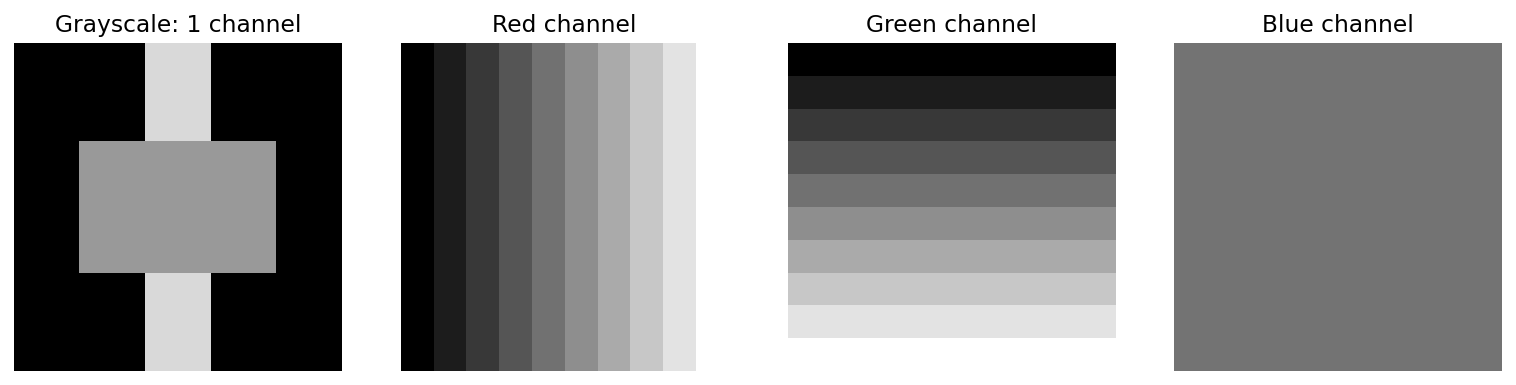

**관찰:** 흑백 이미지는 하나의 픽셀 평면, RGB 이미지는 세 개의 픽셀 평면을 갖는다. 합성곱 필터는 입력 이미지의 **모든 채널을 함께** 살펴본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print('MNIST sample shape:', (28, 28, 1))
print('CIFAR-10 sample shape:', (32, 32, 3))
print('MNIST batch shape:', (64, 28, 28, 1))  # Keras: NHWC

MNIST sample shape: (28, 28, 1)
CIFAR-10 sample shape: (32, 32, 3)
MNIST batch shape: (64, 28, 28, 1)


### Dense와 Conv2D가 보는 입력 범위

- **Dense:** 출력 유닛 하나가 입력의 **전체 특성**을 사용하여 가중합을 계산한다.
- **Conv2D:** 출력의 **각 위치**를 계산할 때 필터가 덮고 있는 **국소 영역**만 사용한다. 그리고 **같은 필터 가중치**를 다른 위치에서도 반복한다.

CNN은 이미지를 작은 부분으로 나누어 따로 훈련하는 모델이 아니다. **한 필터를 공유하면서 이미지 전역을 훑는 모델**이다.

## 2. Conv2D: 하나의 출력값은 어떻게 계산할까?

### 필터(kernel)가 보는 3×3 영역

`Conv2D`의 `kernel_size=3`은 필터가 한 번에 보는 **높이 3, 너비 3**의 공간을 뜻한다. 흑백 이미지라면 3×3의 **9개 픽셀**과 9개 가중치를 각각 곱해서 더하고, 편향을 더하여 출력값 하나를 만든다.

아래 예제에서는 세로 방향의 밝기 변화를 찾는 필터를 직접 정해 본다. 이 가중치는 설명을 위해 고정한 것으로, 실제 CNN의 필터는 **모델 훈련 과정에서 학습**한다.

In [2]:
# 경계가 있는 5×5 흑백 이미지와 3×3 필터
small_image = np.array([
    [0, 0, 0, 10, 10],
    [0, 0, 0, 10, 10],
    [0, 0, 0, 10, 10],
    [0, 0, 0, 10, 10],
    [0, 0, 0, 10, 10],
], dtype='float32')
edge_filter = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1],
], dtype='float32')

patch = small_image[0:3, 1:4]  # 맨 위에서 두 번째 열부터 시작
products = patch * edge_filter
value = products.sum()         # 편향은 0으로 가정

print('Input patch:\n', patch)
print('Filter:\n', edge_filter)
print('Elementwise products:\n', products)
print('One output value:', value)

Input patch:
 [[ 0.  0. 10.]
 [ 0.  0. 10.]
 [ 0.  0. 10.]]
Filter:
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
Elementwise products:
 [[-0.  0. 10.]
 [-0.  0. 10.]
 [-0.  0. 10.]]
One output value: 30.0


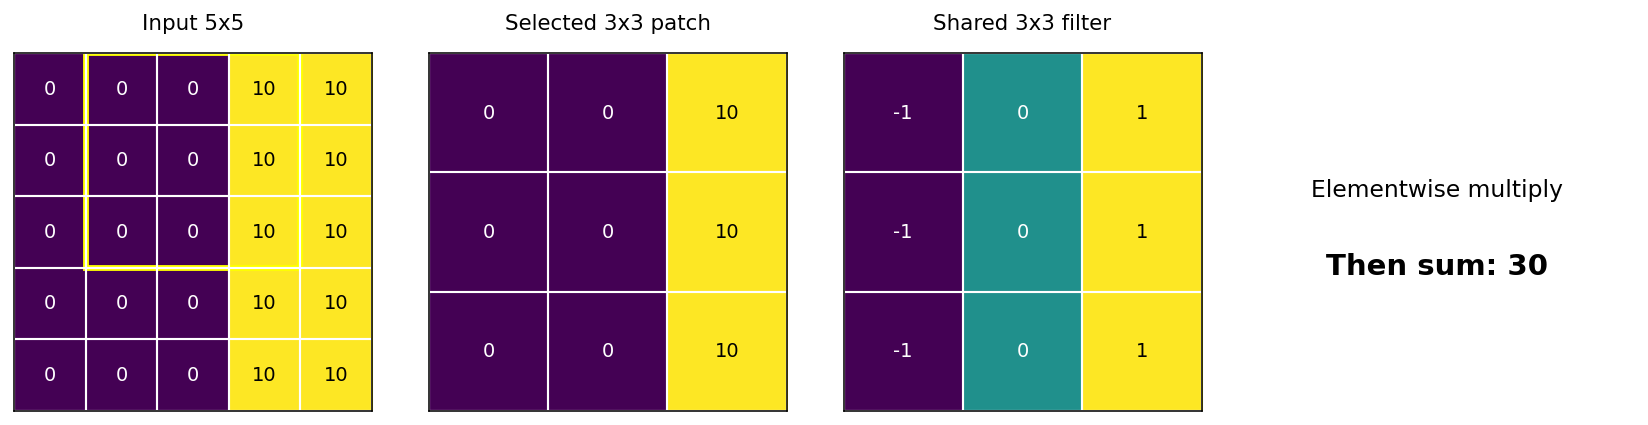

픽셀 값을 $x$, 필터 가중치를 $w$, 편향을 $b$라고 하면, 3×3 필터의 한 출력값은 다음처럼 계산한다.

$$
z = \sum_{a=0}^{2}\sum_{b=0}^{2} x_{a,b}w_{a,b}+\text{bias}
$$

여기서 합 기호는 **9개의 곱을 모두 더한다**는 뜻이다. 위 예제에서는

$$
(0\times-1+0\times0+10\times1)\times3 = 30
$$

이 계산이 이미지의 다른 위치에서도 반복된다. 활성화 함수가 `relu`라면 가중합 이후에 `ReLU(z)=max(0,z)`가 적용된다.

**주의:** 딥러닝 라이브러리가 일반적으로 수행하는 연산은 필터를 뒤집지 않는 *교차상관(cross-correlation)* 이다. 관례적으로 이를 합성곱(convolution)이라 부른다.

### 필터를 이동하면 출력 특성맵이 만들어진다

필터는 이미지의 한 위치에서 값 하나를 계산한 뒤 오른쪽으로 이동한다. 한 줄의 계산이 끝나면 아래로 이동한다. 모든 위치의 결과를 배열에 기록하면 **출력 특성맵(output feature map)**이 된다.

- 입력: `5×5`
- 필터: `3×3`
- 보폭: `1`
- 패딩: 없음(`valid`)
- 출력: `3×3`

왜 3×3이 될까? 필터의 왼쪽 위 시작 위치가 가로·세로 각각 **0, 1, 2**의 세 곳에만 올 수 있기 때문이다.

In [3]:
def valid_conv2d_one_channel(image, kernel, stride=1):
    height, width = image.shape
    kh, kw = kernel.shape
    out_h = (height - kh) // stride + 1
    out_w = (width - kw) // stride + 1
    result = np.zeros((out_h, out_w), dtype='float32')
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i*stride:i*stride+kh, j*stride:j*stride+kw]
            result[i, j] = np.sum(patch * kernel)
    return result

feature_map = valid_conv2d_one_channel(small_image, edge_filter)
print('Output shape:', feature_map.shape)
print('Output feature map:\n', feature_map)
assert feature_map.shape == (3, 3)
assert feature_map[0, 1] == value

Output shape: (3, 3)
Output feature map:
 [[ 0. 30. 30.]
 [ 0. 30. 30.]
 [ 0. 30. 30.]]


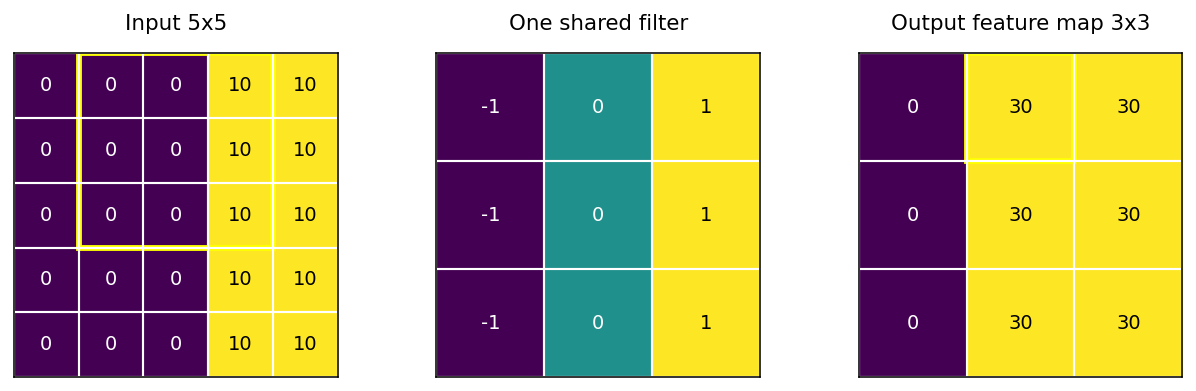

**관찰:** 동일한 필터를 아홉 위치에 적용해 9개의 출력값을 얻는다. 오른쪽의 밝은 값은 필터가 반응하는 위치를 나타낸다.

### 왜 같은 필터를 이미지 전체에 사용할까?

이것을 **가중치 공유(weight sharing)**라고 한다. 한 필터가 세로 방향 경계를 탐지하도록 학습됐다면, 이미지 왼쪽뿐 아니라 오른쪽에서도 **같은 가중치**를 사용해 비슷한 경계에 반응할 수 있다.

장점은 두 가지다.

1. 이미지의 위치마다 완전히 다른 가중치를 학습할 필요가 없어 **파라미터 수가 작다**.
2. 특징이 다른 위치로 이동하면 그에 대응하는 **특성맵의 반응 위치도 이동**한다.

두 번째 성질은 엄밀히 말해 **이동 등변성(translation equivariance)**에 가깝다. 이것만으로 분류 결과가 위치 변화에 항상 동일하다는 뜻은 아니다. 풀링·특성 집계·학습 데이터 등이 위치 변화에 대한 분류의 안정성에 추가로 기여할 수 있다.

**생각해보기:** 필터가 모든 위치에서 동일하다면, 이미지 크기가 두 배로 커질 때 필터의 **가중치 개수**도 두 배로 늘어날까?

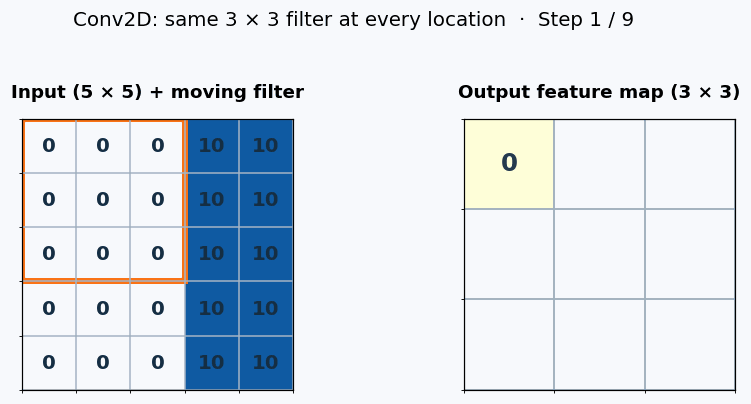

**관찰:** 주황색 테두리의 3×3 영역이 이동할 때마다 오른쪽 특성맵에 값이 하나씩 채워진다. **필터 가중치는 바뀌지 않고, 입력 패치만 바뀐다.** 9개 위치의 계산을 반복해서 살펴보자.

**애니메이션을 읽는 법:** 한 프레임은 한 번의 위치별 곱셈·합산을 의미한다. 같은 3×3 가중치를 9개 위치에 공유한다. 이 예시는 **훈련된 모델의 출력이 아닌 계산 원리를 설명하기 위한 수치 예제**다.

## 3. Conv2D: RGB 채널과 여러 필터

### RGB 입력에서는 필터도 3차원이다

컬러 이미지의 한 픽셀에는 보통 R·G·B 세 값이 있다. 따라서 `kernel_size=3`인 **필터 하나**는 공간 크기가 3×3이고 **깊이는 입력 채널 수 3**이다.

- 입력 텐서: `(높이, 너비, 3)`
- **필터 하나**의 가중치 모양: `(3, 3, 3)`
- 한 위치에서 계산하는 곱셈 수: `3×3×3 = 27`
- **한 필터의 출력:** 모든 채널의 계산을 합친 **출력 특성맵 한 장**

즉, RGB 이미지라고 해서 필터 하나가 반드시 출력 채널 세 개를 만드는 것은 아니다.

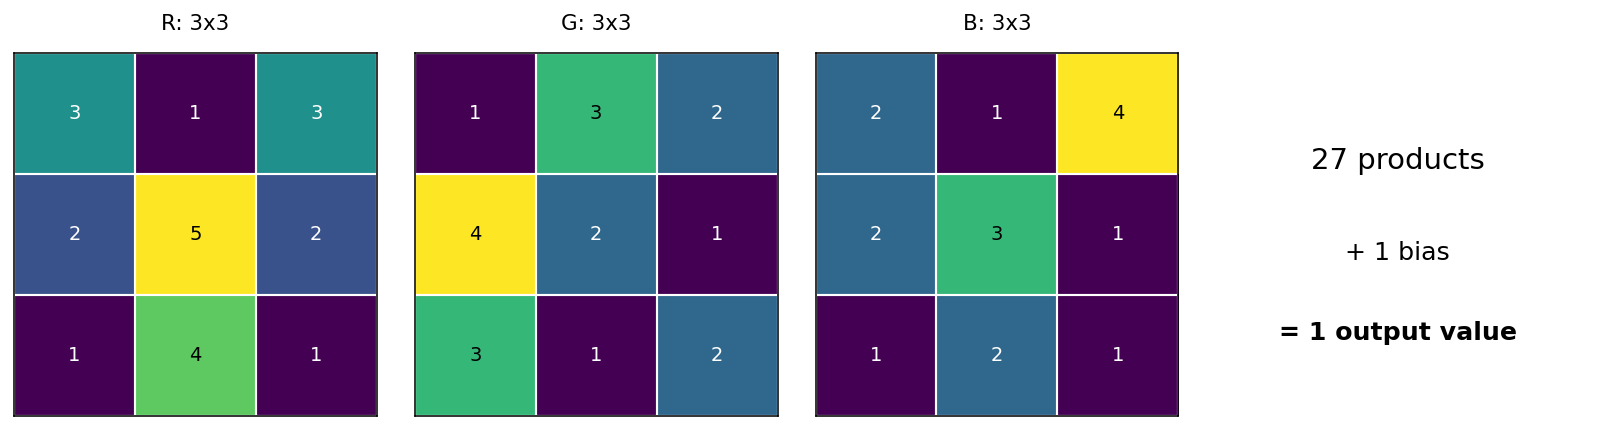

### 필터의 개수는 출력 채널 수를 결정한다

`layers.Conv2D(filters=32, kernel_size=3)`에서 `filters=32`는 서로 다른 필터를 **32개 학습**한다는 뜻이다. 필터 하나가 출력 특성맵 한 장을 만들므로 출력 채널 수가 32가 된다.

예를 들어, 입력이 `(8, 8, 3)`이고 `padding="valid"`, `strides=1`, 필터 수가 6개라면

- 필터 가중치 전체 모양: `(3, 3, 3, 6)` — Keras 기준
- 출력: `(6, 6, 6)`

각 출력 채널이 서로 다른 패턴에 반응할 수 있다. 어떤 필터는 세로 경계, 다른 필터는 가로 경계 등에 반응하도록 학습될 수 있지만, **필터의 의미가 미리 정해져 있는 것은 아니다**.

In [4]:
# 필터 수가 출력 채널 수를 결정한다.
height, width, in_channels = 8, 8, 3
kernel_size, n_filters = 3, 6
out_height = height - kernel_size + 1
out_width = width - kernel_size + 1
print('Filter weights (Keras):', (3, 3, in_channels, n_filters))
print('Output:', (out_height, out_width, n_filters))

Filter weights (Keras): (3, 3, 3, 6)
Output: (6, 6, 6)


### 여러 채널을 합치는 계산을 직접 확인하기

세 채널 각각에서 3×3 영역과 해당 채널의 필터를 곱해 더한 후, **채널별 합도 모두 더하고 편향을 추가**한다. 아래 코드는 3×3 RGB 패치에서 출력값 하나가 만들어지는 과정을 보여준다.

In [5]:
patch_rgb = np.arange(1, 28, dtype='float32').reshape(3, 3, 3)
filter_rgb = np.ones((3, 3, 3), dtype='float32')
channel_sums = (patch_rgb * filter_rgb).sum(axis=(0, 1))
output_value = channel_sums.sum() + 2.0  # bias=2
print('Sum from R, G, B:', channel_sums)
print('One output value:', output_value)
print('Filter shape:', filter_rgb.shape)
assert output_value == 380.0

Sum from R, G, B: [117. 126. 135.]
One output value: 380.0
Filter shape: (3, 3, 3)


### Keras와 PyTorch의 채널 순서 비교

| 구분 | Keras 기본 형식 | PyTorch 기본 형식 |
|---|---|---|
| 한 이미지 | `(H, W, C)` | `(C, H, W)` |
| 배치 | `(N, H, W, C)` | `(N, C, H, W)` |
| 필터 가중치 | `(kH, kW, C_in, C_out)` | `(C_out, C_in, kH, kW)` |

두 라이브러리의 **연산 원리와 출력 채널 수**는 같다. 다만 텐서의 축 순서가 다르므로 데이터를 바꿔 전달해야 한다.

In [6]:
# 두 프레임워크의 입력 형태 예시
keras_shape = (32, 32, 32, 3)     # batch=32, H=32, W=32, C=3
pytorch_shape = (32, 3, 32, 32)   # batch=32, C=3, H=32, W=32
print('Keras batch:', keras_shape)
print('PyTorch batch:', pytorch_shape)

Keras batch: (32, 32, 32, 3)
PyTorch batch: (32, 3, 32, 32)


## 4. Conv2D: 패딩, 보폭, 출력 크기

### 보폭(stride)은 필터를 얼마나 움직일까?

`strides=1`은 필터를 한 칸씩 이동한다. `strides=2`는 두 칸씩 이동한다. 따라서 다른 조건이 같다면 보폭이 커질수록 **출력 특성맵의 공간 크기가 작아진다**.

### 패딩(padding)은 이미지 바깥을 어떻게 다룰까?

- `padding="valid"`: 이미지 바깥으로 필터가 나가지 않게 한다. 주변을 추가로 채우지 않는다.
- `padding="same"`: 출력 크기가 `ceil(입력 크기 / strides)`가 되도록 필요한 패딩을 추가한다. `strides=1`이면 공간 크기를 유지한다.

흔히 0을 추가하는 제로 패딩을 사용한다. **입력 채널 수나 필터 수를 바꾸는 설정은 아니다.**

In [7]:
# H=W=5, kernel=3일 때 각 출력 크기 계산
import math

def output_size_valid(n, kernel, stride):
    return (n - kernel) // stride + 1

def output_size_same(n, stride):
    return math.ceil(n / stride)

for padding, stride in [('valid', 1), ('valid', 2), ('same', 1), ('same', 2)]:
    size = (output_size_valid(5, 3, stride) if padding == 'valid'
            else output_size_same(5, stride))
    print(f'padding={padding:5s}, stride={stride}: {size}x{size}')

padding=valid, stride=1: 3x3
padding=valid, stride=2: 2x2
padding=same , stride=1: 5x5
padding=same , stride=2: 3x3


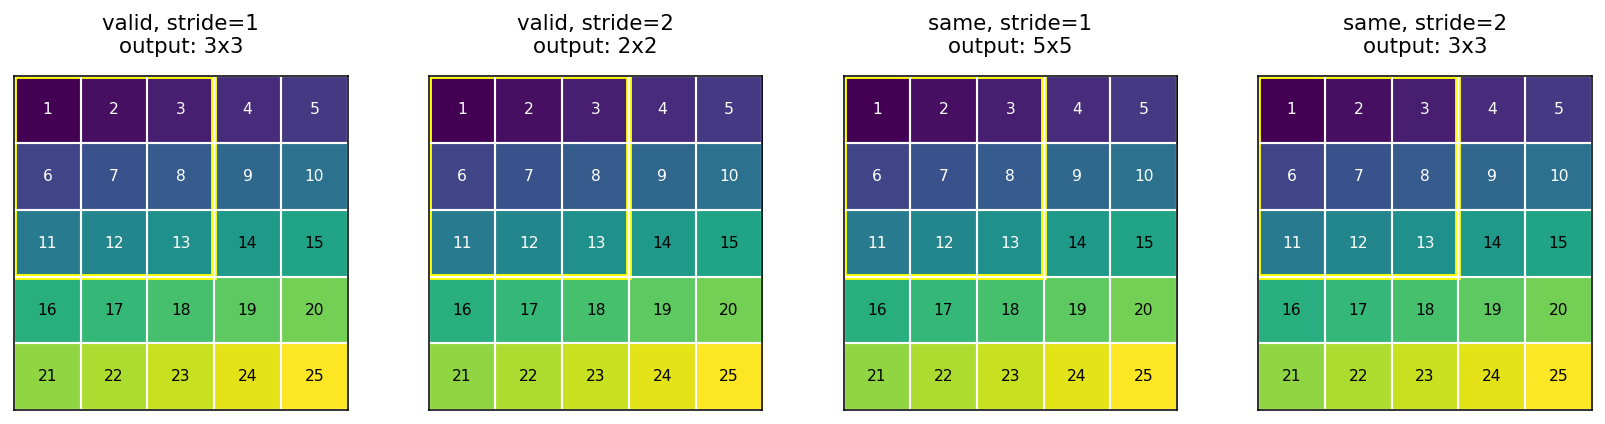

**관찰:** 네 경우 모두 입력과 필터 크기는 동일하지만, 패딩과 보폭에 따라 출력의 높이·너비가 달라진다. 노란 상자는 첫 번째 3×3 영역을 나타낸다.

### 출력 크기를 직접 계산해 보자

패딩이 없는 `valid`의 한 축 출력 크기는 다음과 같다.

$$
O_{\mathrm{valid}}=\left\lfloor\frac{N-K}{S}\right\rfloor+1
$$

- $N$: 입력의 높이 또는 너비
- $K$: 필터 크기(해당 축)
- $S$: 보폭

`same`의 출력 크기는 $\lceil N/S\rceil$이다. 여기서 $\lfloor\ \rfloor$는 내림, $\lceil\ \rceil$는 올림이다.

예를 들어 입력 `5×5`, 필터 `3×3`이면 `valid`/stride 1 → `3×3`, `valid`/stride 2 → `2×2`, `same`/stride 1 → `5×5`, `same`/stride 2 → `3×3`이다.

**참고:** 패딩과 보폭은 높이·너비에 각각 적용된다. 표에는 정사각형 입력과 필터를 가정했다.

### `Conv2D` 코드에서 확인하기

다음 코드는 CNN의 출력 텐서 모양을 확인한다. **파라미터는 아직 학습하지 않아도 출력 크기는 모델 구조만으로 결정**할 수 있다.

In [8]:
import keras
from keras import layers

inputs = keras.Input(shape=(5, 5, 1))
for padding, stride in [('valid', 1), ('valid', 2), ('same', 1), ('same', 2)]:
    y = layers.Conv2D(4, 3, strides=stride, padding=padding)(inputs)
    print(f'{padding:5s}, stride={stride}: {y.shape}')
# (None, H, W, 4): None은 아직 정하지 않은 배치 크기

2026-10-31 12:27:17.921498: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-31 12:27:17.961183: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793417240.535662   46781 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9061 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:01:00.0, compute capability: 8.9


valid, stride=1: (None, 3, 3, 4)
valid, stride=2: (None, 2, 2, 4)
same , stride=1: (None, 5, 5, 4)
same , stride=2: (None, 3, 3, 4)


### NumPy 계산과 실제 Keras Conv2D를 연결하기

앞에서 NumPy로 직접 계산한 3×3 필터를 **Keras `Conv2D`의 가중치로 설정**하면 결과가 동일하게 나온다. `Conv2D`는 새로운 공식을 사용하지 않는다. **필터 가중치로 국소 영역의 값을 계산하는 과정을 효율적으로 수행**한다.

이 예제에서는 훈련하지 않고 우리가 정한 필터 가중치를 그대로 사용한다. 따라서 두 결과가 일치하는지 직접 확인할 수 있다.

In [9]:
# NumPy의 수동 계산과 Conv2D 계산을 비교한다.
fixed_conv = layers.Conv2D(1, 3, padding='valid', use_bias=False)
fixed_conv.build((None, 5, 5, 1))
fixed_conv.set_weights([edge_filter[:, :, None, None]])

keras_result = fixed_conv(small_image[None, :, :, None]).numpy()[0, :, :, 0]
print('Keras Conv2D result:\n', keras_result)
np.testing.assert_allclose(keras_result, feature_map)
print('Matches the NumPy calculation:', True)

Keras Conv2D result:
 [[ 0. 30. 30.]
 [ 0. 30. 30.]
 [ 0. 30. 30.]]
Matches the NumPy calculation: True


2026-10-31 12:27:23.057219: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


### `padding="same"`이 항상 입력 크기를 유지할까?

아니다. **보폭이 1인 경우**에는 높이와 너비가 유지된다. 보폭이 2라면 `same`을 사용해도 출력 높이와 너비는 대략 절반으로 줄어든다.

- `(28,28,1)` → `Conv2D(32,3,padding="same",strides=1)` → `(28,28,32)`
- `(28,28,1)` → `Conv2D(32,3,padding="same",strides=2)` → `(14,14,32)`

**질문:** 보폭을 2로 바꾸면 **필터의 학습 파라미터 수**도 줄어들까? (아니야. 필터의 모양과 개수가 동일하면 파라미터 수는 같다.)

## 5. Conv2D: 학습 파라미터는 얼마나 필요할까?

하나의 필터가 학습하는 가중치는 `커널 높이 × 커널 너비 × 입력 채널 수`개다. 필터가 $C_{out}$개라면 필터 가중치도 그만큼 늘어난다. 편향을 사용하면 필터마다 편향이 하나씩 추가된다.

$$
	ext{Conv2D 파라미터 수} = (K_h	imes K_w	imes C_{in}+1)	imes C_{out}
$$

`use_bias=False`인 경우 `+1`을 제외한다.

예를 들어 **MNIST 입력 `(28,28,1)`에 `Conv2D(32,3)`**을 적용한다면 `3×3×1×32+32 = 320`개다. 이미지의 높이와 너비 자체가 파라미터 수 계산에 직접 곱해지지 않는 이유는 **필터 가중치를 모든 위치에서 공유**하기 때문이다.

In [10]:
def conv_params(kernel, in_channels, out_channels, use_bias=True):
    return kernel * kernel * in_channels * out_channels + (out_channels if use_bias else 0)

print('MNIST 1→32:', conv_params(3, 1, 32))
print('RGB 3→32:  ', conv_params(3, 3, 32))
print('CNN 32→64: ', conv_params(3, 32, 64))
print('Dense 784→32:', 784 * 32 + 32)

MNIST 1→32: 320
RGB 3→32:   896
CNN 32→64:  18496
Dense 784→32: 25120


### Dense와 직접 비교하기

입력의 **모든 784개 픽셀**을 출력 유닛 32개에 연결하는 `Dense(32)`는 `784×32+32 = 25,120`개의 파라미터를 갖는다. 같은 MNIST 입력에 `Conv2D(32,3)`을 적용하면 **320개**다.

이 비교는 출력 구조가 **서로 다른 두 층을 이해하기 위한 예시**이지, 파라미터 수만 보고 어느 층이 더 좋은 모델이라고 결론 내리기 위한 비교는 아니다. Dense 출력은 32개 값, Conv2D 출력은 여러 위치에 걸친 32개 **특성맵**이다.

**주의:** `MaxPooling2D`로 공간 크기를 줄여도 이미 정의된 앞선 `Conv2D` 층의 필터 가중치 수는 변하지 않는다.

## 6. 풀링과 여러 합성곱 층의 결합

### 맥스 풀링은 무엇을 계산할까?

`MaxPooling2D(pool_size=2)`는 각 채널의 **2×2 영역에서 최댓값**을 하나 선택한다. 기본 보폭도 2이므로 일반적으로 높이·너비가 각각 절반이 된다.

풀링에는 필터 가중치를 학습하는 과정이 없다. 단, 위치가 바뀌면 어떤 값이 선택되는지는 달라질 수 있다.

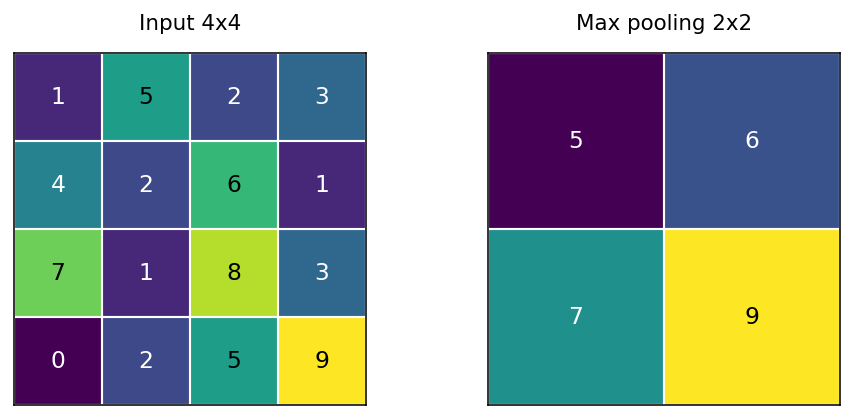

In [11]:
image4 = np.array([[1, 5, 2, 3],
                   [4, 2, 6, 1],
                   [7, 1, 8, 3],
                   [0, 2, 5, 9]])
pooled = image4.reshape(2, 2, 2, 2).max(axis=(1, 3))
print('Pooled:\n', pooled)
assert pooled.tolist() == [[5, 6], [7, 9]]

Pooled:
 [[5 6]
 [7 9]]


### 채널 수는 어떻게 변할까?

입력이 `(26,26,32)`이고 `MaxPooling2D(2)`를 적용하면 출력은 `(13,13,32)`이다. 높이·너비는 줄지만 **채널 수 32는 그대로**다.

반면 `Conv2D(64,3,padding="same")`을 적용하면 출력 채널 수가 **64**로 바뀐다. 즉, 합성곱은 **학습하는 필터의 수**로 채널을 정하고, 풀링은 각 채널의 공간 크기를 줄이는 역할을 한다.

### 합성곱층을 여러 번 쌓으면 무엇이 달라질까?

처음에는 작은 국소 패턴(예: 가로·세로 경계)에 반응하고, 층이 깊어지면서 앞선 층의 특성을 조합하여 **더 넓은 영역과 복잡한 형태**를 표현할 수 있다.

보폭 1인 3×3 합성곱을 연속 적용한다고 가정하면

- 첫 번째 층의 출력값 하나는 원본 입력의 **3×3** 영역에 의존한다.
- 두 번째 층의 출력값 하나는 원본 입력의 **5×5** 영역에 의존한다.
- 세 번째 층의 출력값 하나는 원본 입력의 **7×7** 영역에 의존한다.

이를 **수용 영역(receptive field)**이라고 한다. 패딩·보폭·풀링 등을 사용하면 실제 수용 영역의 증가 방식은 달라진다.

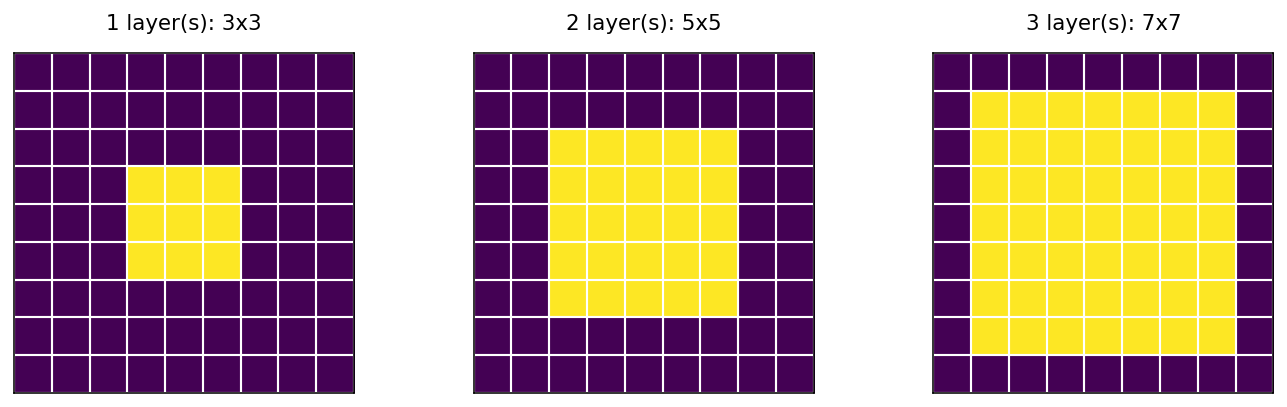

### Flatten과 GlobalAveragePooling2D

CNN의 마지막에는 각 채널의 정보를 분류층으로 전달한다. 대표적인 방법은 다음과 같다.

- `Flatten()`: `(H,W,C)`의 모든 값을 길이 `H×W×C`인 벡터로 펼친다.
- `GlobalAveragePooling2D()`: **채널마다 전체 공간의 평균을 계산**해 길이 `C`인 벡터를 만든다.

예를 들어 `(7,7,128)`의 출력이면 `Flatten()`은 6,272개 값, `GlobalAveragePooling2D()`는 128개 값을 제공한다. 두 연산 모두 자체적으로 학습할 가중치는 없지만, 뒤에 오는 분류층의 파라미터 수에는 큰 차이가 생길 수 있다.

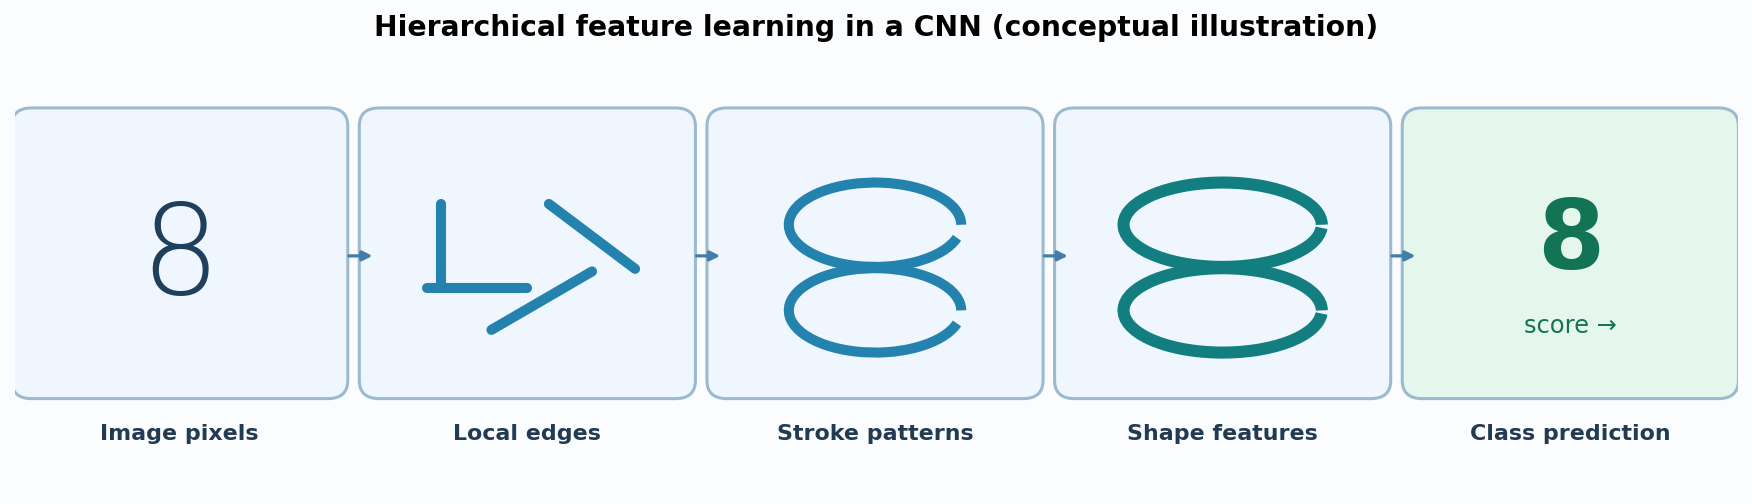

**관찰:** 앞쪽 층에서는 국소 경계 같은 단순한 패턴을, 뒤쪽 층에서는 여러 정보를 결합한 더 복잡한 패턴을 표현할 수 있다. **이 그림은 개념도이며 특정 모델에서 실제로 학습한 특성맵은 아니다.**

**질문:** 첫 번째 합성곱층의 필터가 이미지를 분류할 수 있을까? 보통은 아니다. 여러 단계에서 국소 특성을 조합하고, 마지막에 분류층이 클래스별 점수로 연결한다. 단, 층마다 어떤 특징이 나타나는지는 **데이터와 훈련 결과에 따라 달라진다.**

## 7. MNIST CNN을 층별로 읽어 보기

다음 모델은 `Conv2D` 세 개, `MaxPooling2D` 두 개, `GlobalAveragePooling2D`, `Dense`를 사용한다.

입력 `(28,28,1)`이 어떻게 변환되는지 **출력 크기와 채널 수**를 따라가 보자. 분류 문제이므로 마지막에 10개 클래스의 점수를 만들어 Softmax를 적용한다.

In [12]:
inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

| 단계 | 출력 모양(배치 제외) | 중요한 변화 |
|---|---|---|
| 입력 | `28×28×1` | 흑백 이미지 |
| Conv2D(32,3,same) | `28×28×32` | 필터 32개 → 채널 32 |
| MaxPooling2D(2) | `14×14×32` | 공간 크기 절반 |
| Conv2D(64,3,same) | `14×14×64` | 채널 64 |
| MaxPooling2D(2) | `7×7×64` | 공간 크기 절반 |
| Conv2D(128,3,same) | `7×7×128` | 채널 128 |
| GlobalAveragePooling2D | `128` | 채널별 평균 |
| Dense(10, softmax) | `10` | 클래스별 예측 점수 |

**핵심:** 공간 크기는 주로 풀링과 보폭에 의해 바뀌고, 출력 채널 수는 **합성곱 필터 수**로 결정된다.

### 특성맵을 보면 무엇을 알 수 있을까?

중간 합성곱층의 출력은 여러 장의 특성맵으로 이루어진다. 어떤 위치에서 값이 크다면 그 필터가 **그 위치의 입력 패턴에 강하게 반응**했다는 뜻이다. 같은 이미지라도 필터마다 반응 영역이 다를 수 있다.

다만 **특성맵은 사람이 지정한 의미의 설명 그림이 아니다.** 학습된 필터가 계산한 활성화 값이므로 사람이 직관적으로 이름 붙이기 어려울 수 있다.

**확인 질문:** 특성맵 32장은 반드시 '윤곽선', '수직선' 등의 고정된 32가지 의미를 갖는가? (아니다. 학습 결과에 따라 다르다.)

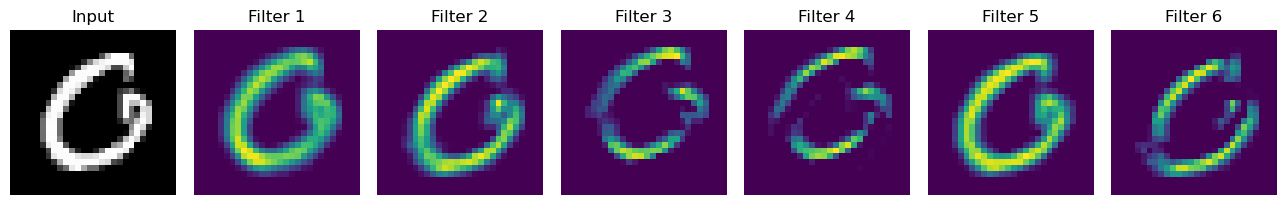

**실제 학습된 CNN의 특성맵:** 왼쪽 입력 숫자 하나에 대해 첫 합성곱층의 서로 다른 필터 6개가 만든 활성화를 비교한다. **보라·초록 등 색상은 값을 표시하는 시각화 색상이지, 원본 이미지의 색이 아니다.**

**관찰 → 해석:** 필터마다 같은 숫자의 서로 다른 위치에 반응한다. 특정 색상의 밝기만으로 “이 필터는 정확히 세로선 전용”이라고 단정하지 않는다. 학습된 가중치와 더 많은 입력에서의 반응을 함께 봐야 한다.

## 8. 작은 이미지 데이터셋과 데이터 증식

고양이와 개를 구별하는 문제는 **이진 분류**다. CIFAR-10에서 고양이(cat)와 개(dog) 클래스만 선택하면 한 이미지의 타깃은 `0` 또는 `1`로 표현할 수 있다.

- MNIST: 10개 숫자 → `Dense(10, softmax)`와 다중 클래스 교차엔트로피
- 고양이·개: 2개 클래스 → `Dense(1, sigmoid)`와 이진 교차엔트로피

**왜 데이터가 적으면 어려울까?** 모델이 훈련 이미지의 배경, 구도, 특정 무늬만 기억하면 새 사진에서 잘못 분류할 수 있기 때문이다. 이런 현상은 검증 손실이 다시 증가하는 등 **과대적합**의 형태로 드러날 수 있다.

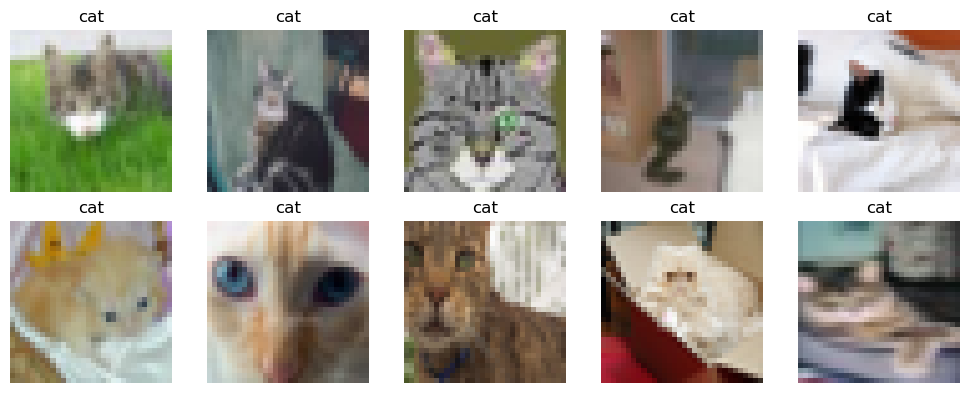

**예시 이미지:** CIFAR-10의 고양이 사진들. 해상도가 32×32이므로 이미지의 형태와 배경이 단순하지 않을 때는 특징을 구분하기 어려울 수 있다.

### 데이터 증식은 원본 데이터 수를 늘리는 것일까?

데이터 증식(data augmentation)은 이미지를 무작위로 변형해 **훈련 중 보게 되는 모습의 다양성**을 높이는 방법이다. 보통 매번 새로운 원본 사진을 수집하는 것은 아니며, 여러 에포크에서 같은 이미지가 다른 변형으로 제시될 수 있다.

| 증식 기법 | 의미 | 확인할 점 |
|---|---|---|
| `RandomFlip("horizontal")` | 좌우 반전 | 반전해도 클래스가 같은가? |
| `RandomRotation(0.10)` | 최대 ±36도 회전 | 객체의 형태가 유지되는가? |
| `RandomTranslation(0.10,0.10)` | 높이·너비의 최대 약 ±10% 이동 | 객체가 지나치게 잘리지 않는가? |
| `RandomZoom(0.07)` | 크기 변화 | 주요 부위가 잘리지 않는가? |
| `RandomContrast(0.5)` | 대비 변화 | 색·대비가 지나치게 왜곡되지 않는가? |

증식 기법은 **레이블의 의미가 유지되는 범위에서** 선택해야 한다. 훈련 중 증식을 사용하더라도 검증·테스트는 보통 **증식하지 않은 이미지**로 평가한다.

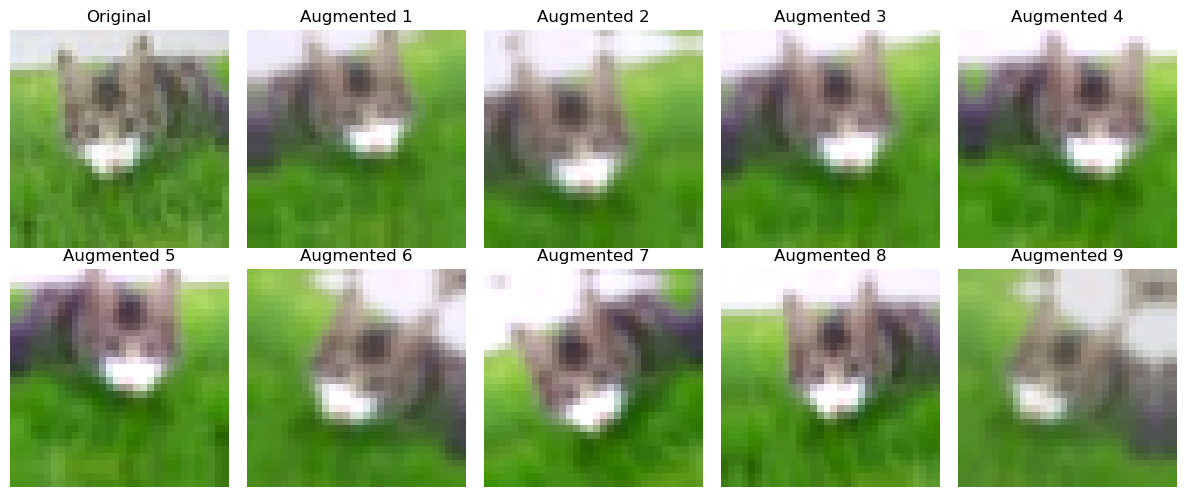

**데이터 증식 사례:** 동일한 고양이 사진에 반전·회전·이동·확대/축소 등의 무작위 변환을 여러 번 적용한 결과. 각 이미지는 **원본 고양이와 같은 클래스**다. 32×32 저해상도 이미지에서는 변형에 따라 디테일이 뭉개질 수 있다.

**비교:** 원본과 증식된 사진을 비교하면서 귀·얼굴처럼 분류에 중요한 부위가 남아 있는지 살펴보자. 변화가 크기만 하다고 좋은 증식은 아니다. 증식 강도는 검증 손실·정확도로 판단한다.

In [13]:
# 작은 이미지에서 데이터 증식을 구성하는 예시
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.07),
])
# 훈련 시 training=True로 무작위 변환을 사용한다.
# 검증·테스트에서는 변형되지 않은 입력으로 평가한다.

## 9. 사전훈련된 CNN 재사용하기: 전이 학습과 미세 조정

### 왜 새 CNN을 처음부터 훈련하지 않을까?

소량의 이미지로 큰 CNN을 처음부터 학습하면 좋은 특성을 학습하기 어려울 수 있다. 대규모 이미지로 훈련한 CNN의 앞부분에는 **경계·질감·형태 등 일반적인 시각적 패턴에 유용한 가중치**가 포함될 수 있다.

전이 학습(transfer learning)은 이를 **특성 추출 기저(base)**로 재사용하는 방법이다.

1. 사전훈련된 CNN에서 기존의 분류 출력층을 제외한다.
2. 기저를 **동결(`trainable=False`)**한다.
3. 해결할 문제에 맞는 새 출력층을 붙인다.
4. 새 출력층만 훈련하고 검증 데이터로 성능을 확인한다.

이때 사전훈련에 사용한 이미지와 현재 데이터가 얼마나 유사한지, 원본 이미지 해상도, 전처리 방식이 결과에 영향을 준다.

### Xception을 특성 추출기로 사용하기

Xception은 **채널 분리 합성곱, 배치 정규화, 잔차 연결**을 결합한 CNN 아키텍처다. 이미지 분류 모델의 상위 분류층을 제외하고 특성 추출 부분을 이용할 수 있다.

```python
base = keras.applications.Xception(
    weights="imagenet", include_top=False,
    input_shape=(96, 96, 3),
)
base.trainable = False
```

- `weights="imagenet"`: 사전훈련된 가중치를 가져온다.
- `include_top=False`: ImageNet용 분류층을 제외한다.
- `input_shape=(96,96,3)`: 여기서 사용할 이미지 크기를 정한다.

CIFAR-10의 32×32 이미지를 96×96으로 확대하더라도 **새로운 시각 정보가 생성되는 것은 아니다**. Xception 입력값은 `[-1, 1]` 범위에 맞춰야 한다.

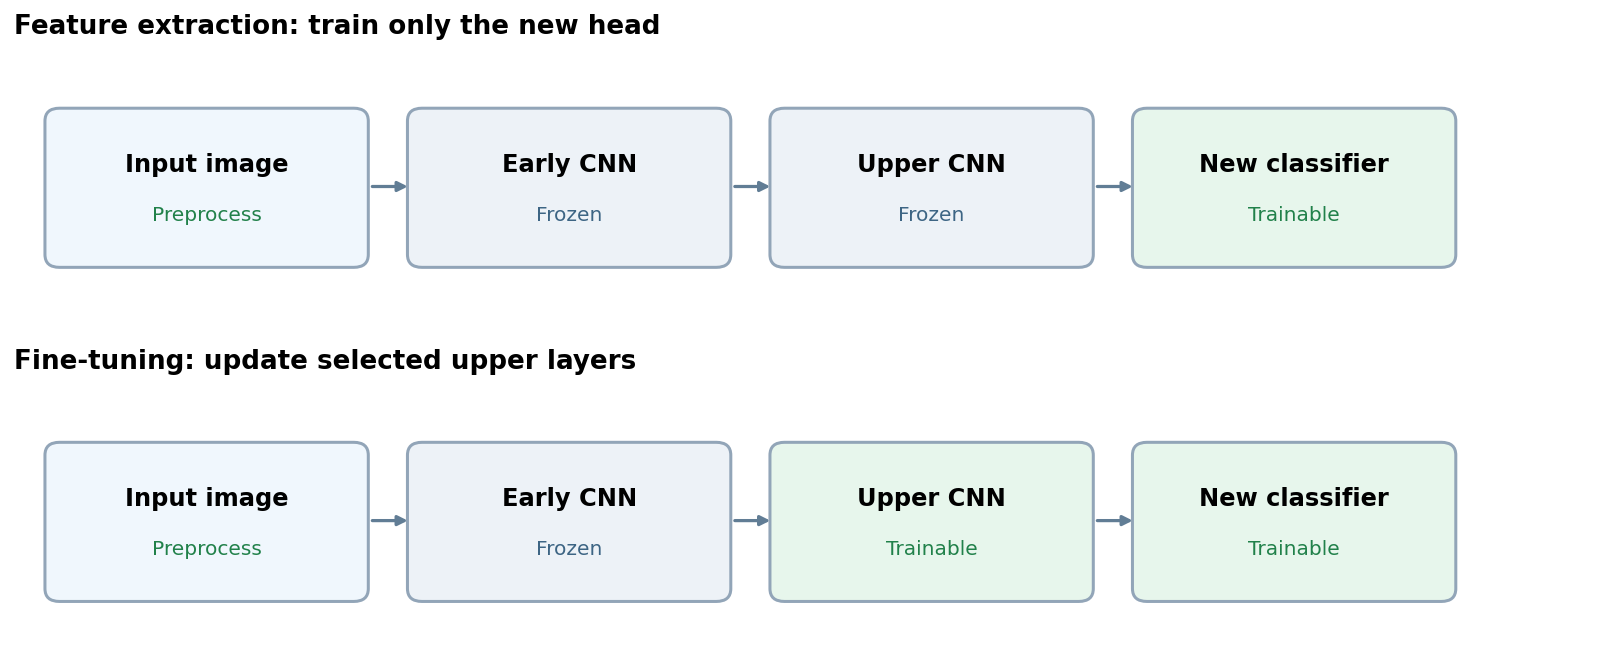

**전이 학습과 미세 조정의 차이:** 특성 추출 단계에서는 CNN 기저 전체를 동결한다. 미세 조정 단계에서는 기저의 상위 일부 층만 훈련 가능하게 바꾸고, 새로운 분류층도 함께 학습한다. **동결된 층의 가중치는 업데이트되지 않는다.**

### 새 분류층은 어떤 모양인가?

Xception 기저가 마지막에 **여러 채널의 특성맵**을 출력하면, `GlobalAveragePooling2D`로 채널별 값을 하나씩 모은 뒤 `Dense(1, sigmoid)`로 고양이·개를 예측할 수 있다.

```python
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Resizing(96, 96)(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
transfer_model = keras.Model(inputs, outputs)
```

이 구조에서 `base.trainable=False`인 동안에는 **사전훈련된 특성 추출기의 가중치가 변하지 않고**, 새로 붙인 분류층의 가중치를 주로 학습한다.

### 미세 조정(fine-tuning)은 전이 학습과 어떻게 다를까?

미세 조정은 기저 전체를 새로 훈련하는 것이 아니라, **상위 일부 층을 동결 해제**하고 **작은 학습률**로 추가 훈련하는 방법이다. 앞쪽의 일반적인 이미지 특징은 보존하면서 목표 문제에 도움이 되는 상위 특징을 일부 조정하려는 목적이다.

순서가 중요하다.

1. 기저를 동결한 상태에서 새 분류층을 먼저 훈련한다.
2. 기저의 상위 일부 층만 학습 가능하게 바꾼다.
3. BatchNormalization 층은 필요에 따라 동결하고, 추론 모드를 유지한다.
4. **학습 가능한 층을 변경한 뒤에는 `compile()`을 다시 실행**한다.
5. 학습률을 낮춰 추가 훈련한다.

**판단:** 미세 조정이 언제나 전이 학습보다 성능을 높이는 것은 아니다. 훈련·검증 손실과 데이터 크기, 모델의 복잡도를 함께 확인해야 한다.

## 10. 이미지 분류를 넘어: 컴퓨터 비전의 문제 유형

CNN으로 뽑은 이미지 특성은 분류 이외의 작업에도 활용할 수 있다. 중요한 차이는 **모델이 예측해야 할 타깃의 형태**다.

| 문제 | 모델이 답할 질문 | 출력 예시 |
|---|---|---|
| 이미지 분류 | 무엇이 있는가? | 클래스 점수 |
| 객체 탐지 | 무엇이 **어디에** 있는가? | 클래스·경계 상자·신뢰도 |
| 시맨틱 분할 | 픽셀마다 무엇인가? | 픽셀별 클래스 |
| 인스턴스 분할 | 같은 클래스의 개별 객체를 구별할 수 있는가? | 객체별 마스크와 클래스 |

특히 시맨틱 분할에서는 같은 클래스에 속한 여러 객체가 동일한 클래스 레이블을 갖는다. 반면 인스턴스 분할에서는 각각을 구분할 수 있어야 한다.

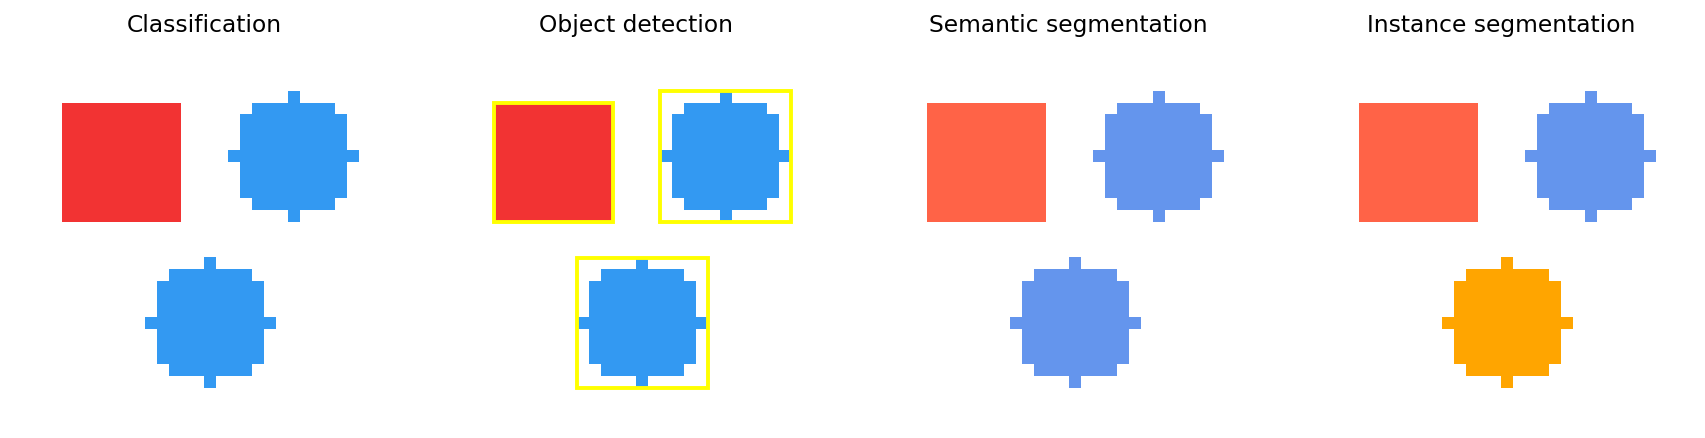

**관찰:** 시맨틱 분할에서는 두 원이 같은 색이고, 인스턴스 분할에서는 두 원이 서로 다른 색이다. 이 그림은 **타깃 형태를 설명하기 위한 인공 예시**이며 실제 모델의 예측 결과는 아니다.

### Faster R-CNN은 객체의 위치를 어떻게 찾을까?

객체 탐지는 **클래스 분류와 위치 예측**을 함께 수행한다. Faster R-CNN은 대표적인 **2단계(two-stage) 객체 탐지기**다.

1. **Backbone(CNN):** 이미지 특성을 추출한다. 예를 들어 ResNet-50을 사용할 수 있다.
2. **FPN:** 서로 다른 크기의 물체를 다루기 위해 여러 해상도의 특성을 결합한다.
3. **RPN:** 물체가 있을 가능성이 높은 후보 영역을 생성한다.
4. **RoI Align + 탐지 헤드:** 후보 영역의 특성을 모아 객체 클래스를 예측하고 경계 상자를 보정한다.
5. 중복 후보를 정리하는 등의 후처리를 거쳐 **`boxes`, `labels`, `scores`**를 출력한다.

**질문:** 이미지 분류 모델이 고양이가 있다고만 답할 때, 객체 탐지 모델은 추가로 무엇을 출력해야 할까?

### 신뢰도 임곗값은 무엇을 바꿀까?

`score_threshold=0.30`은 신뢰도 점수가 0.30 이상인 후보를 남긴다는 뜻이다. 임곗값을 높이면 보통 표시되는 후보 수는 줄어든다. 그러나 틀린 탐지가 모두 없어지거나 실제 객체가 반드시 남는 것은 아니다.

신뢰도 임곗값을 설정할 때는 **오탐(false positive)**과 **미탐(false negative)**을 함께 생각해야 한다. 이때 0.8이라는 점수를 아무 조건 없이 "실제 정답일 확률이 정확히 80%"라고 해석해서는 안 된다.

## 11. CNN 아키텍처의 세 가지 개선 아이디어

CNN이 깊어지고 커질수록 **훈련의 안정성, 연산량, 정보 전달**이 중요해진다. 대표적인 설계 방법 세 가지는 다음과 같다.

1. **잔차 연결(Residual connection):** 중간 층을 건너뛰는 경로를 만든다.
2. **배치 정규화(Batch Normalization):** 중간 활성화의 분포를 정규화하고 학습 가능한 크기·이동 조정을 적용한다.
3. **채널 분리 합성곱(Depthwise Separable Convolution):** 공간 방향의 합성곱과 채널 간 결합을 분리한다.

세 방법은 해결하려는 문제가 서로 달라서 **하나의 아키텍처에서 함께 사용할 수 있다**.

### 잔차 연결: 입력 정보를 더하기

잔차 블록은 보통 다음 형태로 이해할 수 있다.

$$
y = F(x) + x
$$

- $F(x)$: 합성곱 등의 변환을 거친 출력
- $x$: 별도 경로로 전달된 입력
- $+$: 같은 위치의 값끼리 더하는 연산

입력과 출력의 높이·너비·채널 수가 같아야 직접 더할 수 있다. 다르면 `1×1` 합성곱 등의 투영 연산으로 모양을 맞출 수 있다.

잔차 연결은 깊은 네트워크에서 정보와 기울기가 전달될 수 있는 경로를 제공한다. 다만 **잔차 연결을 넣는 것만으로 성능 향상을 보장하는 것은 아니다**.

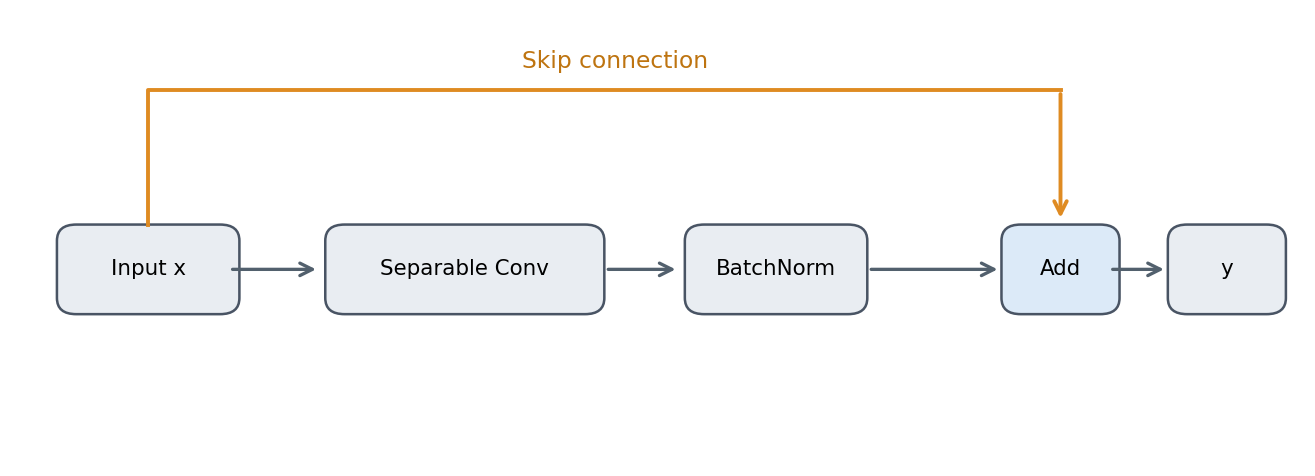

### 배치 정규화: 합성곱의 중간 출력 정규화

`BatchNormalization`은 훈련 배치의 통계 등을 사용해 중간 출력을 정규화하고, 학습 가능한 배율과 이동량을 적용한다. 학습 시와 추론 시의 통계 처리 방식이 다르다.

- **훈련 모드:** 배치의 평균·분산을 이용하고 이동 통계량을 갱신한다.
- **추론 모드:** 일반적으로 훈련 중 축적된 이동 평균·분산을 사용한다.

따라서 사전훈련된 Xception을 미세 조정할 때는 작은 데이터셋이나 작은 배치의 통계가 예측을 흔들 수 있으므로 **BatchNormalization을 동결하거나 추론 모드로 유지**하는 설계가 자주 사용된다.

배치 정규화는 **데이터의 픽셀을 [0,1]로 변환하는 입력 전처리**와 다른 작업이다.

### 채널 분리 합성곱: 연산을 두 단계로 나누기

일반적인 `Conv2D`는 공간상의 3×3 패턴과 채널 간 결합을 **한 번에** 학습한다. 채널 분리 합성곱은 두 단계로 나눈다.

1. **Depthwise convolution:** 입력 채널마다 독립적으로 공간 필터를 적용한다.
2. **Pointwise convolution:** `1×1` 합성곱으로 채널들을 결합하여 원하는 출력 채널 수를 만든다.

PyTorch에서는 `groups=in_channels`인 `nn.Conv2d`와 `kernel_size=1`인 `nn.Conv2d`의 조합으로 표현할 수 있다.

이 방식은 일반 합성곱보다 파라미터와 연산량을 줄일 수 있지만, **항상 정확도가 더 높은 것은 아니다**.

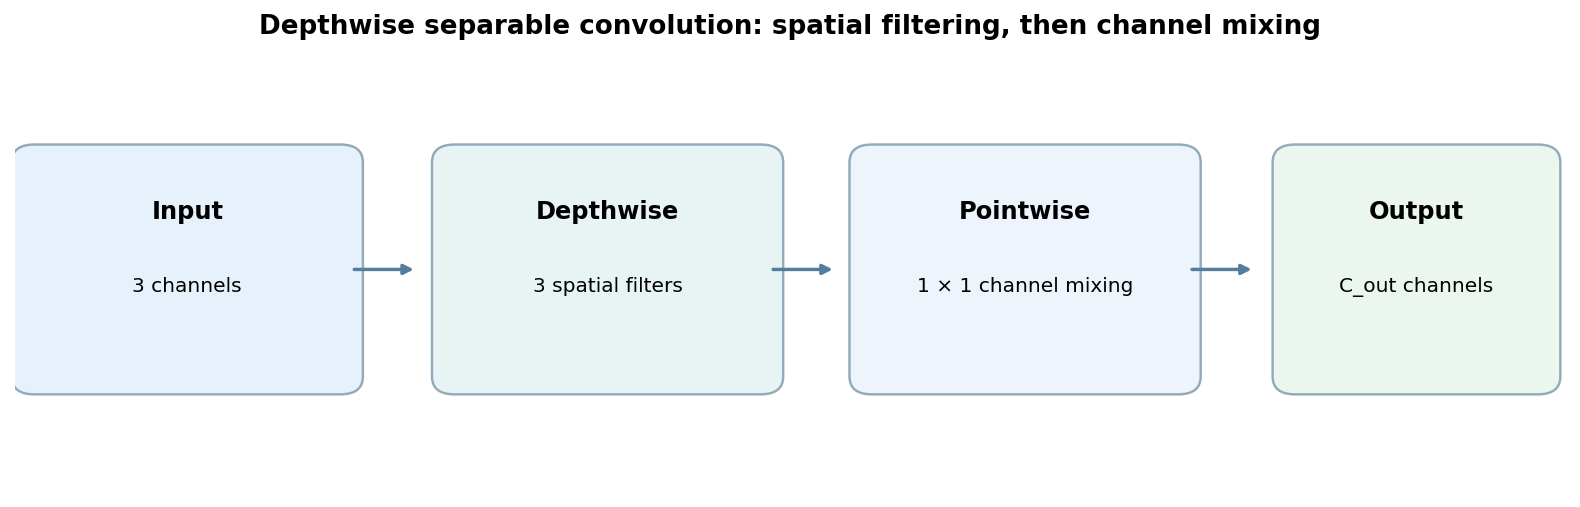

**관찰:** Depthwise 합성곱은 각 입력 채널에서 공간 필터를 따로 적용하고, Pointwise의 `1×1` 합성곱은 채널을 결합해 새로운 출력 채널을 만든다.

### 파라미터 수를 비교하면?

입력 채널 32개를 출력 채널 64개로 바꾸는 3×3 합성곱(편향 제외)을 가정한다.

- **일반 합성곱:** $3\times3\times32\times64 = 18,432$
- **Depthwise:** $3\times3\times32 = 288$
- **Pointwise:** $1\times1\times32\times64 = 2,048$
- **채널 분리 합성곱 합계:** $288+2,048 = 2,336$

같은 입력·출력 채널 수라도 내부 계산 구조가 달라 파라미터 수가 크게 줄어든다.

In [14]:
# 일반 합성곱과 채널 분리 합성곱(편향 제외) 비교
C_in, C_out, k = 32, 64, 3
regular_count = k*k*C_in*C_out
separable_count = k*k*C_in + C_in*C_out
print('Regular Conv2D:', regular_count)
print('Depthwise + pointwise:', separable_count)
print('Ratio:', round(separable_count / regular_count, 3))
assert (regular_count, separable_count) == (18432, 2336)

Regular Conv2D: 18432
Depthwise + pointwise: 2336
Ratio: 0.127


### Xception: 세 가지 방법을 하나의 모델에 결합

Xception은 많은 `SeparableConv2D` 층과 `BatchNormalization`, `Add`로 이루어진 잔차 연결을 사용한다. 모델의 큰 흐름은 다음과 같다.

| 부분 | 역할 |
|---|---|
| **Entry Flow** | 초기 합성곱과 다운샘플링으로 기본 특성 추출 |
| **Middle Flow** | 채널 분리 합성곱과 잔차 연결 블록을 **8회 반복**해 특징을 변환 |
| **Exit Flow** | 더 고수준의 특징을 추출하고 마지막 특성맵을 출력 |

전체 Xception을 이해할 때 모든 층 이름을 외울 필요는 없다. **한 블록의 주 경로에서 특성을 변환하고, 건너뛰기 경로로 입력 정보를 전달해 더한다**는 구조가 핵심이다.

**주의:** Xception을 단순화한 교육용 PyTorch 모델은 세 가지 설계 아이디어를 확인하기 위한 모델이며, ImageNet 사전훈련 Xception의 전체 층 구성이나 가중치를 복제한 모델은 아니다.

## 12. Keras와 PyTorch로 같은 CNN 원리 표현하기

| 개념 | Keras | PyTorch |
|---|---|---|
| 2차원 합성곱 | `layers.Conv2D` | `nn.Conv2d` |
| 맥스 풀링 | `layers.MaxPooling2D` | `nn.MaxPool2d` |
| 전역 평균 풀링 | `layers.GlobalAveragePooling2D` | `nn.AdaptiveAvgPool2d(1)` |
| 배치 정규화 | `layers.BatchNormalization` | `nn.BatchNorm2d` |
| 잔차 연결 | `layers.Add()` | `x + skip` |
| 채널별 합성곱 | `layers.SeparableConv2D` 안에 포함 | `nn.Conv2d(groups=C_in)` |
| 출력 | Softmax/Sigmoid 또는 logits | 보통 logits 출력 후 손실 함수에서 처리 |

두 프레임워크의 차이를 단순한 함수 이름의 차이로만 보지 말고, **입력 텐서 모양과 손실 함수가 기대하는 출력값**까지 함께 확인하자.

## 핵심 정리

- **Conv2D:** 필터가 국소 영역의 픽셀값과 가중치를 곱해 더하고, 같은 필터를 여러 위치에 반복 적용하여 특성맵을 만든다.
- **입력 채널:** 필터 하나의 깊이를 결정한다. RGB 입력의 3×3 필터 하나는 `3×3×3` 가중치를 갖는다.
- **필터 수:** 출력 채널 수를 결정한다. 필터 32개라면 출력 특성맵 32개다.
- **패딩·보폭:** 출력의 **높이와 너비**를 결정한다. `same`도 보폭 2에서는 공간 크기를 줄인다.
- **가중치 공유:** 파라미터 수를 줄이고 동일한 국소 패턴을 여러 위치에서 찾을 수 있게 한다.
- **풀링:** 각 채널의 공간 정보를 요약하며, 학습할 필터 가중치는 없다.
- **데이터 증식:** 훈련 중 이미지의 다양성을 높이고, 검증·테스트에서 일반화를 확인한다.
- **전이 학습·미세 조정:** 사전훈련된 CNN의 특성을 재사용하고, 필요할 때 상위 일부 층을 조정한다.
- **컴퓨터 비전:** 분류는 클래스, 탐지는 클래스·경계 상자, 분할은 픽셀 또는 인스턴스 단위의 출력을 다룬다.
- **Xception:** 채널 분리 합성곱·배치 정규화·잔차 연결을 결합한 CNN이다.

## 확인 문제

1. 흑백 이미지 `(28,28,1)`에 `Conv2D(32,3,padding="same")`을 적용하면 출력 모양은 무엇인가?
2. RGB 이미지에 `3×3` 필터 **하나**를 적용하면 가중치는 몇 개인가? (편향 제외)
3. `filters=64`는 무엇을 의미하며 출력 텐서에 어떤 영향을 주는가?
4. 입력 `7×7`, 필터 `3×3`, `padding="valid"`, `strides=2`이면 출력의 공간 크기는?
5. `padding="same"`, `strides=2`를 쓰면 입력의 공간 크기가 반드시 유지되는가?
6. `Conv2D(32,3)`에서 입력 이미지의 크기만 바꾸면 가중치 수가 달라지는가?
7. `MaxPooling2D(2)`에서 입력 `(14,14,64)`의 출력 크기는?
8. `GlobalAveragePooling2D()`에 `(7,7,128)`이 들어가면 출력은 몇 차원인가?
9. 전이 학습에서 Xception의 `include_top=False`, `trainable=False`는 각각 무엇을 뜻하는가?
10. 객체 탐지와 이미지 분류의 출력 타깃은 어떻게 다른가?
11. 시맨틱 분할과 인스턴스 분할은 같은 클래스의 객체 둘을 어떻게 다루는가?
12. Xception에서 채널 분리 합성곱, 배치 정규화, 잔차 연결은 각각 어떤 역할을 하는가?

### 확인 문제 해설

1. `(28,28,32)` (배치 크기 제외).
2. `3×3×3 = 27`개.
3. 필터 64개를 학습하며, 출력 채널이 64개가 된다.
4. `floor((7-3)/2)+1=3`이므로 `3×3`.
5. 아니다. 출력 크기는 대략 절반(`ceil(N/2)`)이다.
6. 아니다. 채널 수와 필터 설정이 같으면 가중치 수는 동일하다.
7. `(7,7,64)`.
8. 128차원.
9. 기존 분류층을 제외하고, 기저의 가중치를 동결한다.
10. 분류는 이미지 전체의 클래스, 탐지는 각 객체의 클래스와 위치를 예측한다.
11. 시맨틱 분할에서는 같은 클래스 레이블, 인스턴스 분할에서는 서로 다른 객체 마스크/ID로 구분한다.
12. 공간·채널 계산 분리로 효율 향상, 중간 출력 정규화, 입력과 변환 출력을 더해 정보 경로 확보.